# Earth–Moon Halo Families

Graphs the L1 and L2 halo families computed by pseudo-arclength continuation.

Each family is seeded with a Richardson 3rd-order guess, polished by the
differential corrector, then continued with the same PAC engine that drives
the Lyapunov families (`compute_halo_family` in `orbits.py`). Three views:

1. **x–z projection** — the classic family fan, colored by Jacobi constant.
2. **3D view** — the out-of-plane loop structure.
3. **Family characteristics** — amplitude and period vs. Jacobi, where the
   folds (the reason PAC is needed) show up as turnbacks.

In [1]:
import sys, os, contextlib
sys.path.insert(0, '../src')   # adjust if cr3bp*.py / orbits.py live elsewhere
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
%matplotlib inline

# Importing orbits.py executes the exploratory script at the top of that file,
# which prints a wall of setup output. Silence just the import.
with open(os.devnull, 'w') as _dn, contextlib.redirect_stdout(_dn):
    import orbits

from orbits import compute_halo_family, halo_periodicity_constraint, family_tangent
from cr3bp_3d import (richardson_halo_seed, halo_corrector,
                      integrate_with_stm_3d, jacobi_constant_3d,
                      MU_EARTH_MOON as MU)
from cr3bp import find_lagrange_points

mu = MU

## Seed and continue each family

`northern=True` here means a **+z excursion** at both points. The Richardson
`c_n` coefficients flip sign from L1 to L2, so the raw seed flag maps to
opposite hemispheres at the two points — `first_orbit` absorbs that flip so
both families come out on the same side for a clean comparison. Drop the
`if point == 'L1'` mapping to get the raw per-point convention instead.

In [2]:
def first_orbit(point, Az=0.05, northern=True):
    """Richardson seed -> corrector -> one on-family halo X = [x0, z0, vy0, T_half]."""
    seed_flag = northern if point == 'L1' else (not northern)   # +z at both points
    seed, _, _ = richardson_halo_seed(Az, mu, point=point, northern=seed_flag)
    s0, T, ok = halo_corrector(seed, mu)
    if not ok:
        raise RuntimeError(f"{point} corrector failed to converge")
    return np.array([s0[0], s0[2], s0[4], T / 2.0])

def amplitude_direction(X):
    """Tangent sign that marches toward larger out-of-plane amplitude."""
    _, dF, _ = halo_periodicity_constraint(X, mu)
    t = family_tangent(dF)
    return t if np.sign(t[1]) == np.sign(X[1]) else -t

def halo_family(point, Az=0.05, northern=True, ds=0.01, n_orbits=130):
    X0 = first_orbit(point, Az=Az, northern=northern)
    return compute_halo_family(X0, ds=ds, n_orbits=n_orbits, mu=mu,
                               initial_direction=amplitude_direction(X0),
                               verbose=False)

In [3]:
fam_L1 = halo_family('L1', ds=0.01, n_orbits=130)
fam_L2 = halo_family('L2', ds=0.01, n_orbits=130)

for name, fam in [('L1', fam_L1), ('L2', fam_L2)]:
    z0 = np.array([o['z0'] for o in fam])
    C  = np.array([o['jacobi'] for o in fam])
    print(f"{name}: {len(fam):3d} orbits | z0 in [{z0.min():+.3f}, {z0.max():+.3f}]"
          f" | C in [{C.min():.3f}, {C.max():.3f}]")

L1: 130 orbits | z0 in [+0.008, +0.478] | C in [2.756, 3.174]
L2: 130 orbits | z0 in [-0.076, -0.007] | C in [3.015, 3.152]


## x–z projection

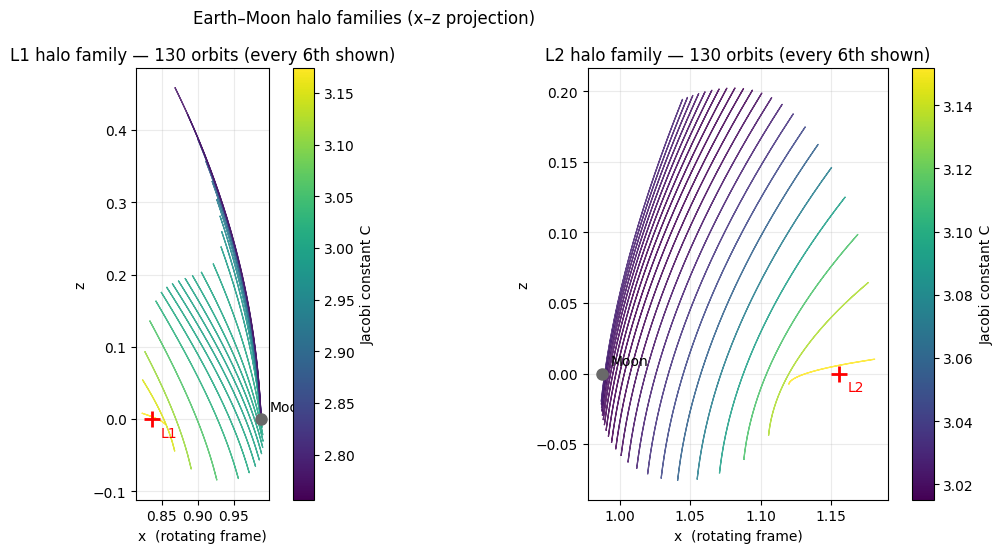

In [4]:
def orbit_xyz(o, n=500):
    sol = integrate_with_stm_3d(o['state0'], [0, o['period']], mu,
                                t_eval=np.linspace(0, o['period'], n))
    return sol.y[0], sol.y[1], sol.y[2]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, (name, fam) in zip(axes, [('L1', fam_L1), ('L2', fam_L2)]):
    C = np.array([o['jacobi'] for o in fam])
    norm = Normalize(C.min(), C.max())
    for o in fam[::6]:
        x, y, z = orbit_xyz(o)
        ax.plot(x, z, color=cm.viridis(norm(o['jacobi'])), lw=0.9, alpha=0.85)
    ax.plot(1 - mu, 0, 'o', color='dimgray', ms=8)
    ax.annotate('Moon', (1 - mu, 0), textcoords='offset points', xytext=(6, 6))
    lp = find_lagrange_points(mu)[name]
    ax.plot(lp[0], 0, '+', color='red', ms=11, mew=2)
    ax.annotate(name, (lp[0], 0), textcoords='offset points', xytext=(6, -13), color='red')
    ax.set_xlabel('x  (rotating frame)'); ax.set_ylabel('z')
    ax.set_title(f'{name} halo family — {len(fam)} orbits (every 6th shown)')
    ax.set_aspect('equal'); ax.grid(alpha=0.25)
    sm = cm.ScalarMappable(norm=norm, cmap=cm.viridis); sm.set_array([])
    fig.colorbar(sm, ax=ax, label='Jacobi constant C', fraction=0.046, pad=0.04)
fig.suptitle('Earth–Moon halo families (x–z projection)')
fig.tight_layout(); plt.show()

## 3D view

The out-of-plane structure. Small members sit near the plane (near the planar
Lyapunov bifurcation); large members climb into the near-rectilinear regime
where the orbit wraps close to the Moon.

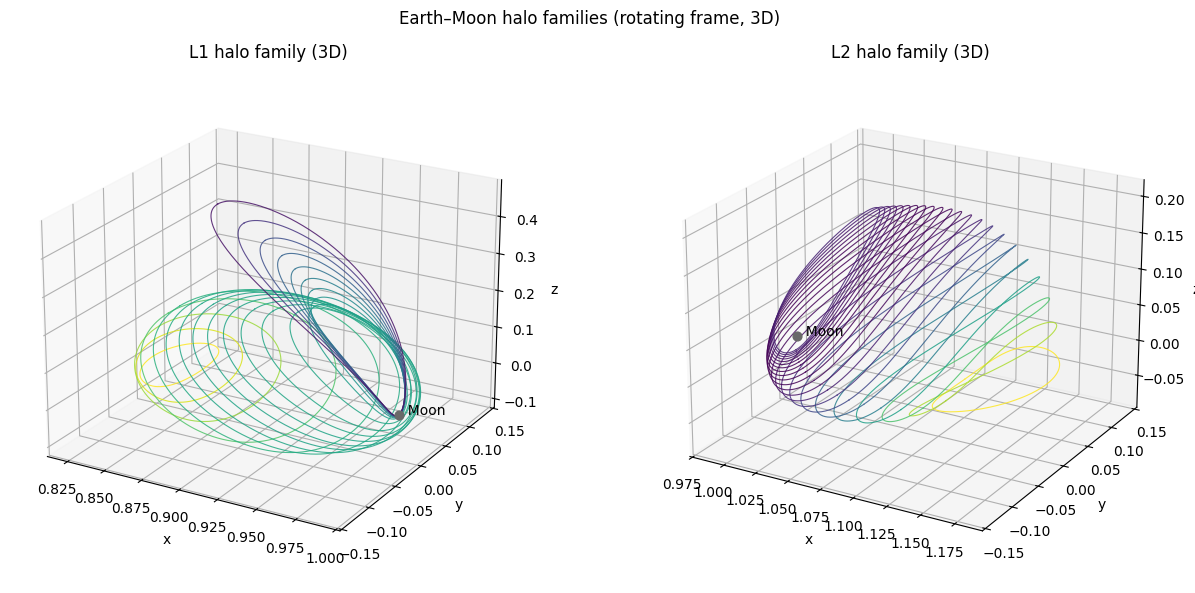

In [5]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (enables 3d projection)

fig = plt.figure(figsize=(13, 6))
for i, (name, fam) in enumerate([('L1', fam_L1), ('L2', fam_L2)], start=1):
    ax = fig.add_subplot(1, 2, i, projection='3d')
    C = np.array([o['jacobi'] for o in fam])
    norm = Normalize(C.min(), C.max())
    for o in fam[::6]:
        x, y, z = orbit_xyz(o)
        ax.plot(x, y, z, color=cm.viridis(norm(o['jacobi'])), lw=0.8, alpha=0.85)
    ax.scatter([1 - mu], [0], [0], color='dimgray', s=40)
    ax.text(1 - mu, 0, 0, '  Moon')
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.set_title(f'{name} halo family (3D)')
    ax.view_init(elev=22, azim=-60)
fig.suptitle('Earth–Moon halo families (rotating frame, 3D)')
fig.tight_layout(); plt.show()

## Family characteristics

Each family plotted as a curve in (Jacobi, amplitude) and (Jacobi, period).
Where a curve doubles back, the family has folded — natural-parameter
continuation would have stalled there; pseudo-arclength walks straight
through because arclength never reverses.

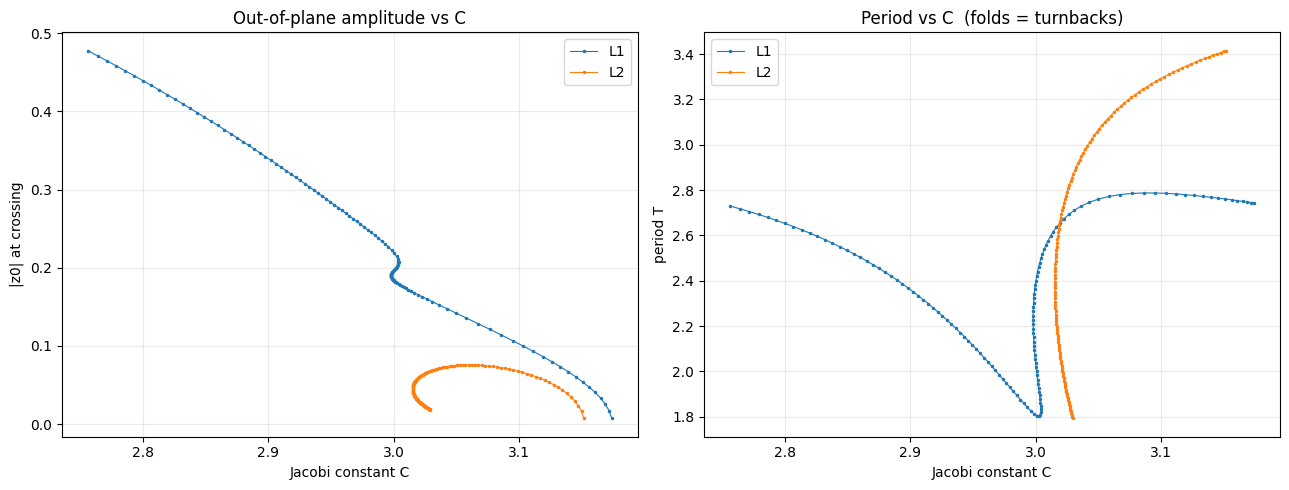

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, fam, color in [('L1', fam_L1, 'C0'), ('L2', fam_L2, 'C1')]:
    C    = np.array([o['jacobi'] for o in fam])
    T    = np.array([o['period'] for o in fam])
    zamp = np.abs([o['z0'] for o in fam])
    axes[0].plot(C, zamp, '.-', ms=3, lw=0.8, color=color, label=name)
    axes[1].plot(C, T,    '.-', ms=3, lw=0.8, color=color, label=name)
axes[0].set_xlabel('Jacobi constant C'); axes[0].set_ylabel('|z0| at crossing')
axes[0].set_title('Out-of-plane amplitude vs C'); axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].set_xlabel('Jacobi constant C'); axes[1].set_ylabel('period T')
axes[1].set_title('Period vs C  (folds = turnbacks)'); axes[1].legend(); axes[1].grid(alpha=0.25)
fig.tight_layout(); plt.show()